# PAGA — HSC compartment

Partition-based Graph Abstraction (Wolf et al. 2019) infers a coarse-grained
connectivity graph between cell clusters. Edge weight = inter-cluster connectivity
relative to a random-graph null; higher = more connected.

**Input:** `output/objects/hsc.h5ad` (SCT-normalised, 50 PCA dims, 30 neighbours)

**Sections**
1. Load + neighbours
2. PAGA at varying edge cutoffs — `res.0.9`
3. PAGA overlaid on UMAP
4. PAGA across resolutions (0.1 → 1.5)

In [1]:
import scanpy as sc
import anndata as ad
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path

matplotlib.rcParams['figure.dpi'] = 120
sc.settings.verbosity = 1

H5AD   = Path('output/objects/hsc.h5ad')
OUT    = Path('output/objects/paga')
OUT.mkdir(parents=True, exist_ok=True)

# Cluster column used throughout the project
CLUST_COL = 'sNN_pca.SCT_30_res.0.9'

# All available resolutions for the cross-resolution panel
RES_COLS = [
    'sNN_pca.SCT_30_res.0.1',
    'sNN_pca.SCT_30_res.0.3',
    'sNN_pca.SCT_30_res.0.5',
    'sNN_pca.SCT_30_res.0.7',
    'sNN_pca.SCT_30_res.0.9',
    'sNN_pca.SCT_30_res.1',
    'sNN_pca.SCT_30_res.1.2',
    'sNN_pca.SCT_30_res.1.5',
]

COND_COLORS = {'WT': '#1f78b4', 'mCh-': '#a6cee3', 'mCh+': '#e31a1c'}

## 1 · Load + build neighbours

In [2]:
adata = sc.read_h5ad(H5AD)
print(adata)

# Ensure cluster column is categorical (required by sc.tl.paga)
for col in RES_COLS:
    adata.obs[col] = adata.obs[col].astype(str).astype('category')

# Build kNN graph on existing PCA (matches pipeline: 30 PCs, 30 neighbours)
# PAGA needs obsp['connectivities'] — recompute from stored PCA.
sc.pp.neighbors(adata, n_neighbors=30, n_pcs=50, use_rep='X_pca', random_state=42)
print('Neighbours computed.')

AnnData object with n_obs × n_vars = 50056 × 11057
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'cell.name', 'tube', 'sample.name', 'sample.name.long', 'compartment', 'nCount_HTO', 'nFeature_HTO', 'percent.mt', 'percent.rp', 'percent.hb', 'count_feat_ratio', 'percent.stress', 'S.Score', 'G2M.Score', 'Phase', 'dm2_max_prop', 'dm2_max_resid', 'dm2_class', 'pass_mt', 'pass_nFeature', 'pass_rp', 'pass_hb', 'pass_qc', 'pass_hto', 'scDblFinder.score', 'scDblFinder.class', 'pass_dbl', 'pass_cell', 'nCount_SCT', 'nFeature_SCT', 'sNN_pca.SCT_30_res.0.1', 'sNN_pca.SCT_30_res.0.3', 'sNN_pca.SCT_30_res.0.5', 'sNN_pca.SCT_30_res.0.7', 'sNN_pca.SCT_30_res.0.9', 'sNN_pca.SCT_30_res.1', 'sNN_pca.SCT_30_res.1.2', 'sNN_pca.SCT_30_res.1.3', 'sNN_pca.SCT_30_res.1.5', 'seurat_clusters', 'cytotrace2_score', 'cytotrace2_potency', 'cytotrace2_relative'
    obsm: 'X_pca', 'X_umap'
Neighbours computed.


In [ ]:
# Compute cluster UMAP positions once — reused for all PAGA overlays
cats      = adata.obs[CLUST_COL].cat.categories
umap_pos  = np.array([
    adata.obsm['X_umap'][adata.obs[CLUST_COL] == c].mean(axis=0)
    for c in cats
])

def _umap_colors(adata, clust_col):
    """Return per-cell hex colors matching scanpy's palette."""
    cats    = list(adata.obs[clust_col].cat.categories)
    palette = adata.uns.get(f'{clust_col}_colors',
                [matplotlib.colors.to_hex(plt.cm.tab20(i / max(len(cats),1)))
                 for i in range(len(cats))])
    cmap = {c: palette[i] for i, c in enumerate(cats)}
    return [cmap[c] for c in adata.obs[clust_col]]

def paga_on_umap(adata, ax, threshold, title, pos, clust_col,
                 scatter_size=1.0, scatter_alpha=0.25,
                 node_size_scale=1.5, edge_width_scale=0.5, fontsize=9):
    """UMAP scatter background + PAGA nodes/edges overlaid."""
    cell_colors = _umap_colors(adata, clust_col)
    ax.scatter(adata.obsm['X_umap'][:, 0], adata.obsm['X_umap'][:, 1],
               c=cell_colors, s=scatter_size, alpha=scatter_alpha,
               linewidths=0, rasterized=True)
    sc.pl.paga(adata, threshold=threshold, pos=pos, ax=ax, show=False,
               title=title, frameon=False, fontsize=fontsize,
               node_size_scale=node_size_scale, edge_width_scale=edge_width_scale)
    ax.axis('off')


## 2 · PAGA at varying edge cutoffs

Using `res.0.9` clusters. Each panel shows the same PAGA graph with a
different `threshold` — edges below the threshold are hidden.

Saved: /project/output/paga/paga_cutoffs_sNN_pca.SCT_30_res.0.9.png


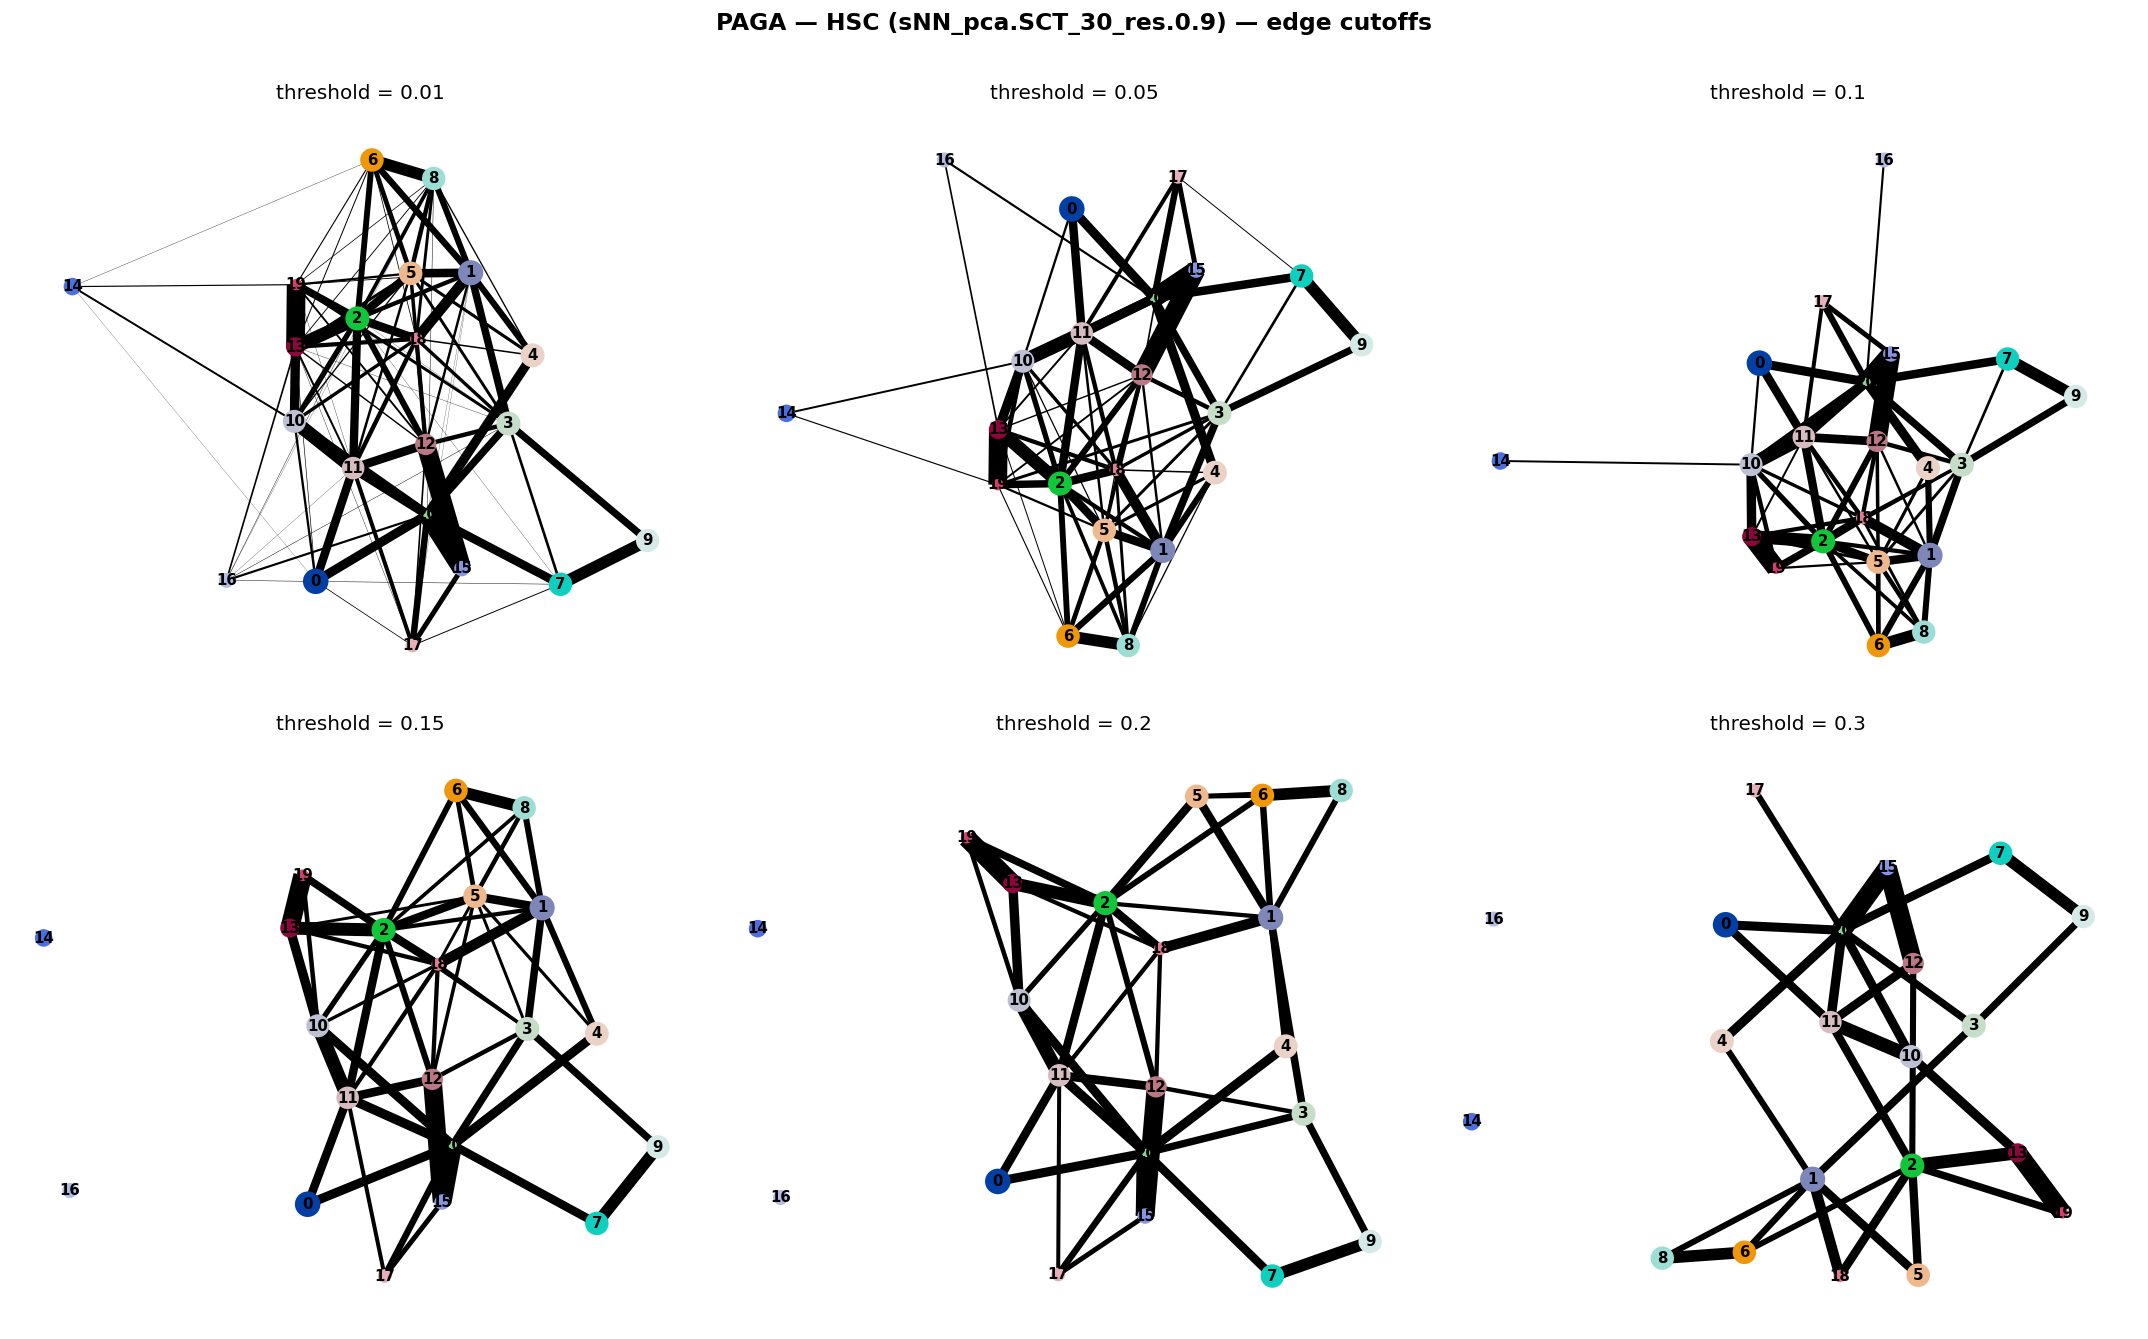

In [3]:
sc.tl.paga(adata, groups=CLUST_COL)

CUTOFFS = [0.01, 0.05, 0.10, 0.15, 0.20, 0.30]

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle(f'PAGA — HSC ({CLUST_COL}) — edge cutoffs (UMAP overlay)',
             fontsize=14, fontweight='bold', y=1.01)

for ax, threshold in zip(axes.flat, CUTOFFS):
    paga_on_umap(adata, ax, threshold=threshold,
                 title=f'threshold = {threshold}',
                 pos=umap_pos, clust_col=CLUST_COL)

plt.tight_layout()
out_path = OUT / f'paga_cutoffs_{CLUST_COL}.png'
fig.savefig(out_path, dpi=150, bbox_inches='tight')
print(f'Saved: {out_path}')
plt.show()


### Edge weight table

In [4]:
conn = adata.uns['paga']['connectivities']
n    = conn.shape[0]
cats = adata.obs[CLUST_COL].cat.categories

rows = []
for i in range(n):
    for j in range(i + 1, n):
        w = conn[i, j]
        if w > 0:
            rows.append({'cluster_A': cats[i], 'cluster_B': cats[j], 'weight': round(float(w), 4)})

edge_df = pd.DataFrame(rows).sort_values('weight', ascending=False)
edge_df.to_csv(OUT / f'paga_edges_{CLUST_COL}.csv', index=False)
print(f'{len(edge_df)} edges total')
edge_df.head(20)

148 edges total


,cluster_A,cluster_B,weight
61,12,15,1.0000
77,13,19,1.0000
92,15,20,1.0000
29,10,11,0.7268
78,13,2,0.6927
147,7,9,0.6249
145,6,8,0.6233
19,1,18,0.5588
53,11,20,0.5044
31,10,13,0.5009


## 3 · PAGA overlaid on UMAP

Node positions placed at the median UMAP coordinates of each cluster.
Three panels: cluster labels / condition split / all samples.

Saved: /project/output/paga/paga_umap_overlay_sNN_pca.SCT_30_res.0.9.png


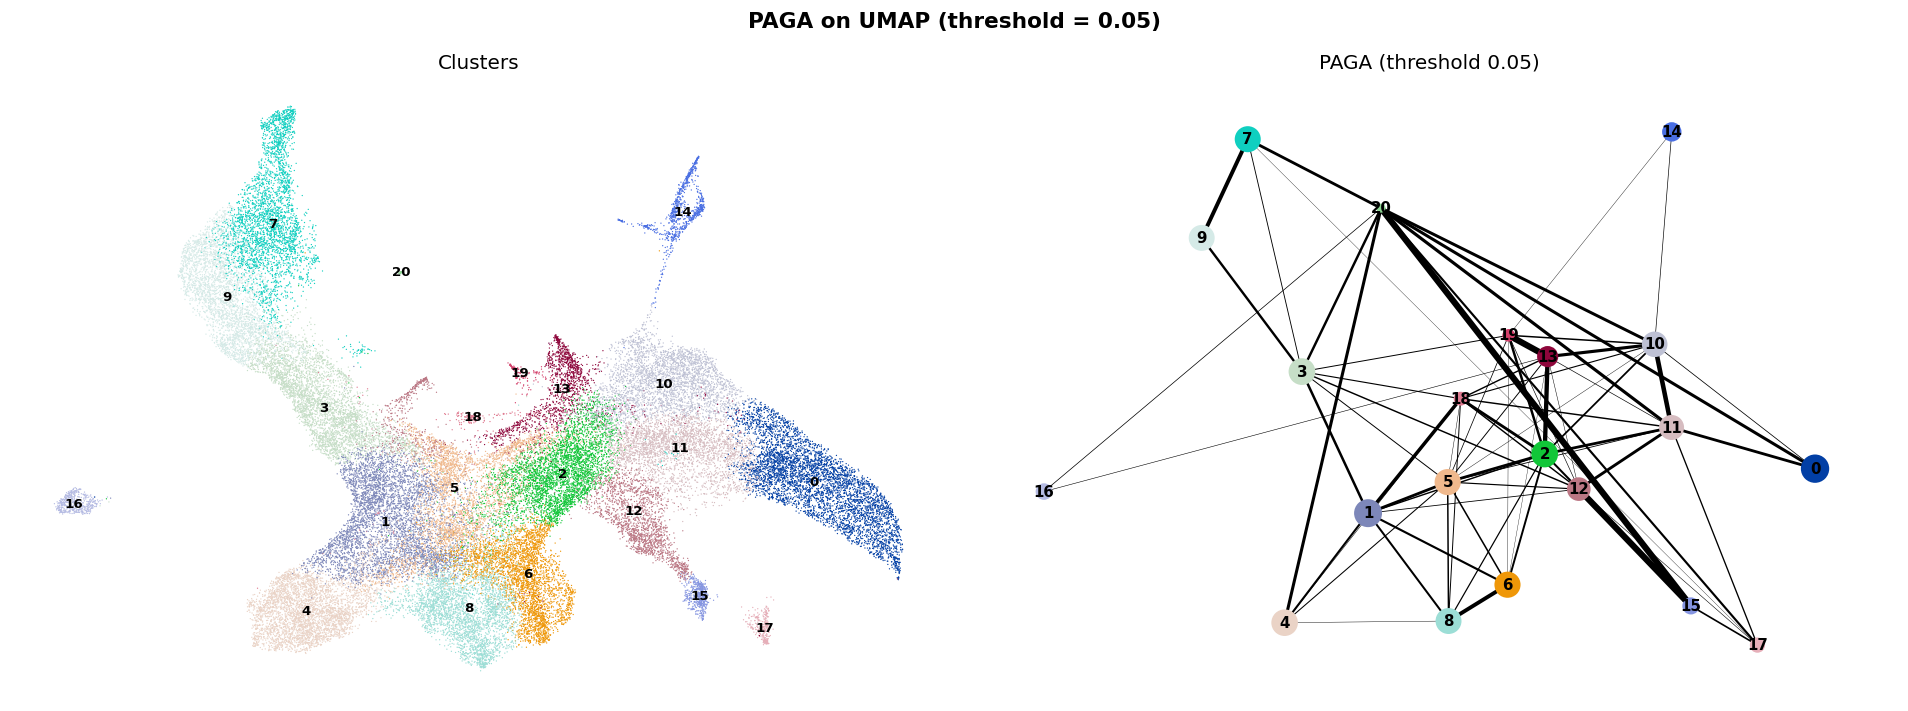

In [13]:
# Section 3 header cell — remove stale content (already handled by paga_on_umap helper)


THRESHOLD_UMAP = 0.05

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(f'PAGA on UMAP (threshold = {THRESHOLD_UMAP})', fontsize=13, fontweight='bold')

# Left: cluster UMAP
sc.pl.umap(adata, color=CLUST_COL, ax=axes[0], show=False,
           legend_loc='on data', legend_fontsize=8,
           title='Clusters', frameon=False)

# Right: PAGA overlaid
paga_on_umap(adata, axes[1], threshold=THRESHOLD_UMAP,
             title=f'PAGA (threshold {THRESHOLD_UMAP})',
             pos=umap_pos, clust_col=CLUST_COL,
             node_size_scale=1.5, edge_width_scale=0.5)

plt.tight_layout()
out_path = OUT / f'paga_umap_overlay_{CLUST_COL}.png'
fig.savefig(out_path, dpi=150, bbox_inches='tight')
print(f'Saved: {out_path}')
plt.show()


Saved: /project/output/paga/paga_across_resolutions.png


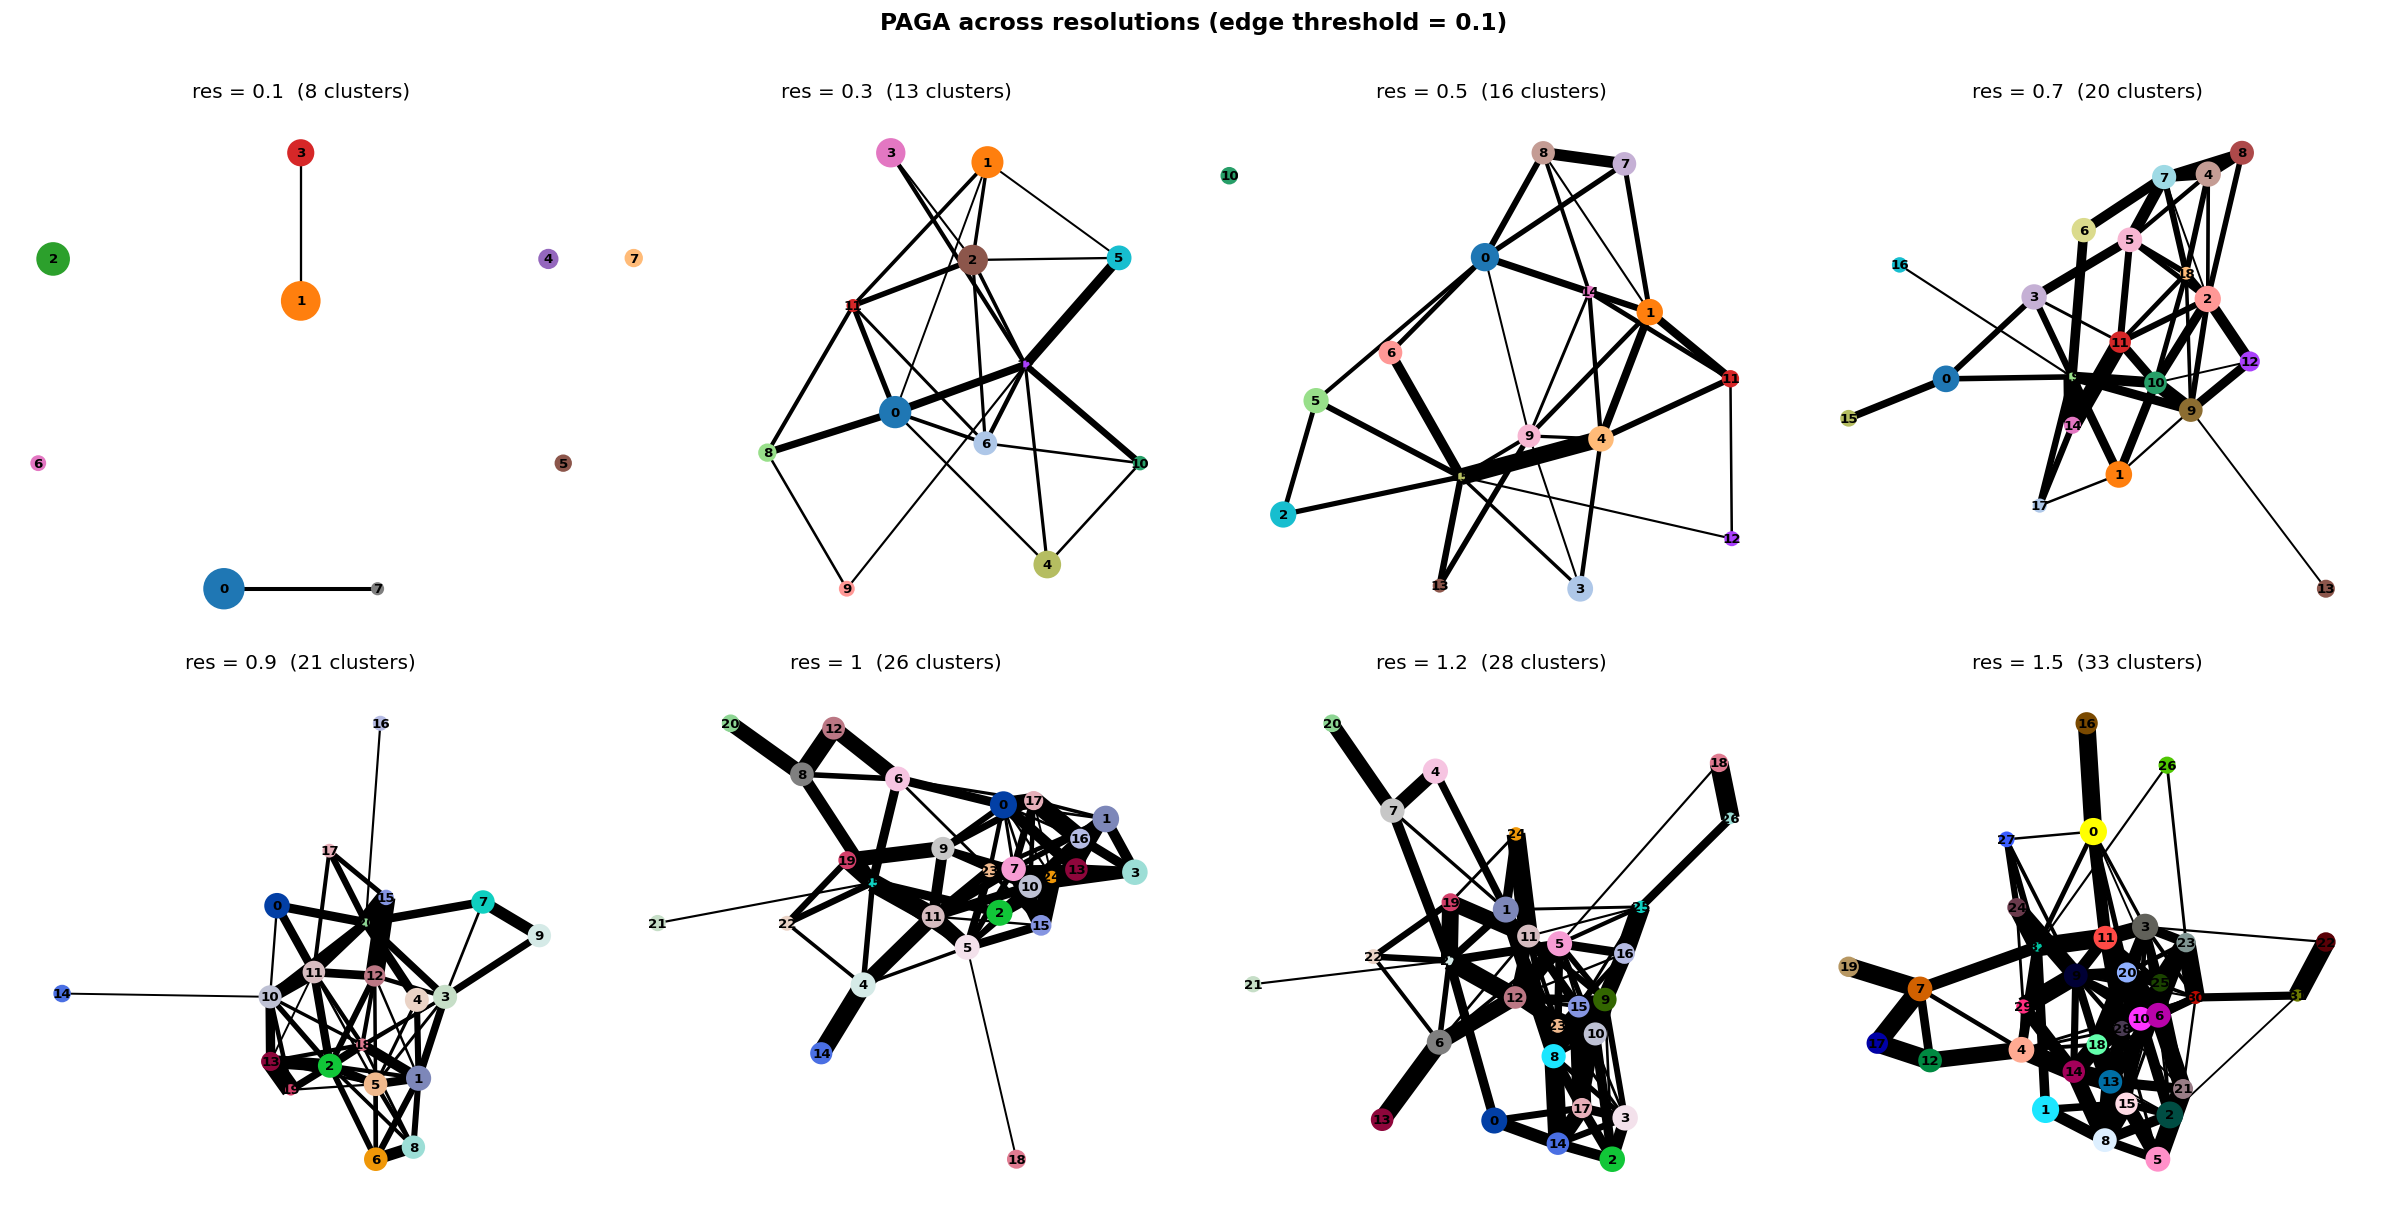

In [6]:
THRESHOLD_RES = 0.10

n_res = len(RES_COLS)
ncols = 4
nrows = int(np.ceil(n_res / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 5))
fig.suptitle(f'PAGA across resolutions (threshold = {THRESHOLD_RES}, UMAP overlay)',
             fontsize=14, fontweight='bold', y=1.01)

for ax, col in zip(axes.flat, RES_COLS):
    sc.tl.paga(adata, groups=col)
    res_label = col.split('res.')[-1]
    n_clust   = adata.obs[col].nunique()
    res_cats  = adata.obs[col].cat.categories
    res_pos   = np.array([
        adata.obsm['X_umap'][adata.obs[col] == c].mean(axis=0)
        for c in res_cats
    ])
    paga_on_umap(adata, ax, threshold=THRESHOLD_RES,
                 title=f'res = {res_label}  ({n_clust} clusters)',
                 pos=res_pos, clust_col=col,
                 scatter_size=0.6, fontsize=8,
                 node_size_scale=1.0, edge_width_scale=1.0)

for ax in axes.flat[n_res:]:
    ax.set_visible(False)

plt.tight_layout()
out_path = OUT / 'paga_across_resolutions.png'
fig.savefig(out_path, dpi=150, bbox_inches='tight')
print(f'Saved: {out_path}')
plt.show()

# Restore paga for primary resolution
sc.tl.paga(adata, groups=CLUST_COL)


In [7]:
out_h5ad = OUT / 'hsc_paga.h5ad'
adata.write_h5ad(out_h5ad)
print(f'Saved: {out_h5ad}')
print('uns keys:', list(adata.uns.keys()))

RuntimeError: `anndata.settings.allow_write_nullable_strings` is False, because writing of `pd.arrays.{StringArray,ArrowStringArray}` is new and not supported in anndata < 0.11, still use by many people. Opt-in to writing these arrays by toggling the setting to True.